# CRISP-DM Stage 2: Data Understanding
## ECG Heartbeat Classification for Analog Devices MAX78002 Edge-AI

---

### Project Context & Objective
Cardiac arrhythmias represent a major cause of global morbidity and mortality. Early automated detection on battery-powered wearable devices can enable continuous patient monitoring and life-saving early interventions. 

In this project, we develop a compact machine learning model to classify ECG heartbeats into four clinically meaningful categories:
- **N**: Normal / Bundle branch block beats
- **S**: Supraventricular ectopic beats (SVEB)
- **V**: Ventricular ectopic beats (VEB)
- **F**: Fusion beats

Target deployment is the **Analog Devices MAX78002 Edge-AI microcontroller**, an ultra-low-power SoC featuring a dedicated CNN hardware accelerator with:
- **Maximum model size**: $\le 2\text{ MB}$ (supported by 2.5 MB weight SRAM, 1.3 MB data SRAM)
- **Quantization**: INT8 fixed-point arithmetic
- **Fixed-size 1D input**: e.g., 256 samples ($711.1\text{ ms}$ @ $360\text{ Hz}$)

---

### Purpose of this Notebook
This notebook fulfills **CRISP-DM Stage 2 (Data Understanding)** by systematically exploring:
1. **Dataset Description (Section 2.1)**: Recording duration, sampling rate, channels, leads, and patient demographics.
2. **Target Classes & Mapping (Section 2.2)**: AAMI EC57 standard 4-class mapping and documented exclusions.
3. **Exploratory Data Analysis (Section 2.3)**: Waveform morphology, lead comparisons, filtering, class distributions, patient heterogeneity, and real-world noise.
4. **Data Quality Audit (Section 2.4)**: Checking missing data, extreme amplitudes, baseline drift, and signal artifacts.
5. **Data Leakage Analysis (Section 2.5)**: Demonstration of why random heartbeat splitting is methodologically flawed, and how our patient-independent DS1/DS2 split prevents leakage.

In [1]:
# Environment Setup & Imports
import sys
import os
import glob
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt
import wfdb

# Add src to python path for modular utilities
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', 'src')))
import data_understanding as du

# Visual styling for clean, publication-quality figures
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.style.use('seaborn-v0_8-whitegrid')

# Print directory configuration
print(f"Dataset directory: {du.DEFAULT_DATA_DIR}")
print(f"Available records: {len(du.ALL_RECORDS)} ({len(du.DS1_RECORDS)} DS1, {len(du.DS2_TEST_RECORDS)} DS2, {len(du.PACED_RECORDS)} Paced)")

Dataset directory: dataset\physionet.org\files\mitdb\1.0.0
Available records: 48 (22 DS1, 22 DS2, 4 Paced)


## 2.1 Dataset Description
### The MIT-BIH Arrhythmia Database

The MIT-BIH Arrhythmia Database (Moody & Mark, 1992; PhysioNet) is the gold-standard reference database for cardiac arrhythmia analysis:
- **Total records**: 48 ambulatory two-channel ECG recordings.
- **Subjects**: 47 distinct subjects (Records 201 and 202 are from the same subject, recorded on the same analog tape).
- **Duration**: Approximately 30 minutes per record ($650,000$ samples each, totaling $\approx 24.3\text{ hours}$).
- **Sampling Frequency**: $360\text{ Hz}$ per channel with 11-bit resolution over a $\pm 10\text{ mV}$ range.
- **Annotations**: Over $110,000$ expert cardiological beat annotations placed at the local R-peak extremum.
- **Channels**: 2 simultaneous ECG leads. Modified Lead II (MLII) is present in 44 of 48 records (channel 0 in 43 records, channel 1 in Record 114). The secondary channel is typically a modified chest lead (V1, V2, V4, or V5).

In [2]:
# Load and inspect dataset metadata across records
meta_df = du.get_dataset_metadata_table()

# Display database overview summary
print("=== MIT-BIH Arrhythmia Database Overview ===")
print(f"Total records in directory : {len(meta_df)}")
print(f"Sampling frequency         : {meta_df['Sampling Rate (Hz)'].iloc[0]} Hz")
print(f"Nominal recording duration : {meta_df['Duration (min)'].mean():.2f} minutes")
print(f"Total beat annotations     : {meta_df['Total Annotations'].sum():,}")

# Summary of available lead combinations
print("\nLead Configuration Breakdown across all 48 records:")
lead_breakdown = meta_df['Leads Available'].value_counts()
for leads, count in lead_breakdown.items():
    print(f"  {leads:<15}: {count:2d} records")

# Display a slice of the metadata table
display_cols = ['Record', 'Split', 'Leads Available', 'Selected Lead', 'Lead Channel Index', 'Duration (min)', 'Total Annotations', 'Clinical Notes']
meta_df[display_cols].head(10)

=== MIT-BIH Arrhythmia Database Overview ===
Total records in directory : 48
Sampling frequency         : 360 Hz
Nominal recording duration : 30.09 minutes
Total beat annotations     : 112,647

Lead Configuration Breakdown across all 48 records:
  MLII, V1       : 40 records
  MLII, V5       :  2 records
  V5, V2         :  2 records
  MLII, V2       :  2 records
  V5, MLII       :  1 records
  MLII, V4       :  1 records


,Record,Split,Leads Available,Selected Lead,Lead Channel Index,Duration (min),Total Annotations,Clinical Notes
0,100,DS2 - Final Test,"MLII, V5",MLII,0,30.09,2274,"69 M 1085 1629 x1; Aldomet, Inderal"
1,101,DS1 - Validation,"MLII, V1",MLII,0,30.09,1874,75 F 1011 654 x1; Diapres
2,102,Paced (Excluded),"V5, V2",V5,0,30.09,2192,84 F 1525 167 x1; Digoxin; The rhythm is paced...
3,103,DS2 - Final Test,"MLII, V2",MLII,0,30.09,2091,"-1 M 742 654 x1; Diapres, Xyloprim"
4,104,Paced (Excluded),"V5, V2",V5,0,30.09,2311,"66 F 1567 694 x1; Digoxin, Pronestyl; The rate..."
5,105,DS2 - Final Test,"MLII, V1",MLII,0,30.09,2691,"73 F 1624 1629 x1; Digoxin, Nitropaste, Prones..."
6,106,DS1 - Validation,"MLII, V1",MLII,0,30.09,2098,24 F 1581 654 x1; Inderal; The PVCs are multif...
7,107,Paced (Excluded),"MLII, V1",MLII,0,30.09,2140,63 M 1340 167 x1; Digoxin; Complete heart bloc...
8,108,DS1 - Validation,"MLII, V1",MLII,0,30.09,1824,"87 F 1227 654 x1; Digoxin, Quinaglute; There i..."
9,109,DS1 - Train,"MLII, V1",MLII,0,30.09,2535,64 M 1508 694 x1; Quinidine; There is first de...


## 2.2 Target Classes & AAMI EC57 Mapping

### Standard 4-Class Mapping
In accordance with the **ANSI/AAMI EC57:1998** standard and the project specifications, we map individual beat annotations into **4 clinically actionable classes**:

| Final Class | Name | Clinical Description | Original MIT-BIH Symbols Included |
| :---: | :--- | :--- | :--- |
| **N** | **Normal** | Normal sinus beats and bundle branch conduction delays | `N` (Normal), `L` (Left BBB), `R` (Right BBB), `e` (Atrial escape), `j` (Nodal escape) |
| **S** | **Supraventricular Ectopic** | Ectopic beats originating in atria or AV junction | `A` (Atrial premature), `a` (Aberrated APB), `J` (Nodal premature), `S` (Supraventricular premature) |
| **V** | **Ventricular Ectopic** | Premature ventricular contractions originating in ventricles | `V` (PVC), `E` (Ventricular escape) |
| **F** | **Fusion** | Hybrid beat from simultaneous ventricular & sinus depolarization | `F` (Fusion of ventricular and normal) |

### Documented Exclusions
1. **Paced Records Excluded**: Records `102`, `104`, `107`, and `217` are paced recordings containing artificial pacemaker pulses (`/`) and fusion of paced beats (`f`). Per standard protocol (de Chazal et al., 2004), these 4 records are excluded from development and test sets.
2. **Rare/Unclassifiable Beats Excluded**: Symbol `Q` (unclassifiable / unknown) and `x` (non-conducted P-wave) are excluded as they do not belong to the 4 classes.
3. **Non-Beat Annotations Excluded**: Rhythm change markers (`+`), signal quality annotations (`~`), ventricular flutter waves (`!`), and isolated artifacts (`|`) are metadata markers, not heartbeats.

In [3]:
# Target Classes Summary Table
target_df = du.get_target_classes_table()
display(target_df)

# Count exact distribution across DS1 (Development) and DS2 (Final Test)
breakdown_df = du.get_class_breakdown_table()

# Filter for the 44 non-paced records (DS1 + DS2)
eval_records = du.DS1_RECORDS + du.DS2_TEST_RECORDS
eval_breakdown = breakdown_df[breakdown_df['Record'].isin(eval_records)]

total_N = eval_breakdown['N'].sum()
total_S = eval_breakdown['S'].sum()
total_V = eval_breakdown['V'].sum()
total_F = eval_breakdown['F'].sum()
total_classified = total_N + total_S + total_V + total_F
total_excluded = eval_breakdown['Excluded'].sum()

print("=== Target Class Totals across Benchmark Records (DS1 + DS2) ===")
print(f"  Class N : {total_N:6,d}  ({total_N / total_classified * 100:6.2f}%)")
print(f"  Class S : {total_S:6,d}  ({total_S / total_classified * 100:6.2f}%)")
print(f"  Class V : {total_V:6,d}  ({total_V / total_classified * 100:6.2f}%)")
print(f"  Class F : {total_F:6,d}  ({total_F / total_classified * 100:6.2f}%)")
print(f"  Total Classified : {total_classified:6,d} beats")
print(f"  Total Excluded   : {total_excluded:6,d} annotations (non-beat markers / unclassifiable)")

,Final Class,Meaning,Original Annotations Included,Clinical Significance
0,N,Normal-type beats,"N (Normal), L (LBBB), R (RBBB), e (Atrial esca...",Dominant healthy or conduction-delayed ventric...
1,S,Supraventricular ectopic beats (SVEB),"A (Atrial premature), a (Aberrated atrial prem...",Beats originating from atria or AV junction ab...
2,V,Ventricular ectopic beats (VEB),"V (Premature ventricular contraction), E (Vent...",Beats originating within ventricular myocardiu...
3,F,Fusion beats,F (Fusion of ventricular and normal beat),Hybrid morphology caused by simultaneous ventr...


=== Target Class Totals across Benchmark Records (DS1 + DS2) ===
  Class N : 90,125  ( 89.48%)
  Class S :  2,781  (  2.76%)
  Class V :  7,009  (  6.96%)
  Class F :    803  (  0.80%)
  Total Classified : 100,718 beats
  Total Excluded   :  3,006 annotations (non-beat markers / unclassifiable)


## 2.3 Exploratory Data Analysis: Raw ECG Waveforms & Channels

### Lead Comparison: MLII vs Secondary Chest Lead
The MIT-BIH recordings provide two simultaneous channels:
- **MLII (Modified Lead II)**: Recorded by placing electrodes along the chest to emulate limb lead II. It aligns directly with the heart's primary electrical axis during ventricular depolarization, making QRS complexes tall, sharp, and easy to detect.
- **Secondary Lead (e.g., V1, V2, or V5)**: Transverse precordial leads that reflect septal and lateral wall depolarization.

In Record 114, the channel order is reversed: **channel 0 is V5, while channel 1 is MLII**. Our pipeline automatically handles this channel swap.

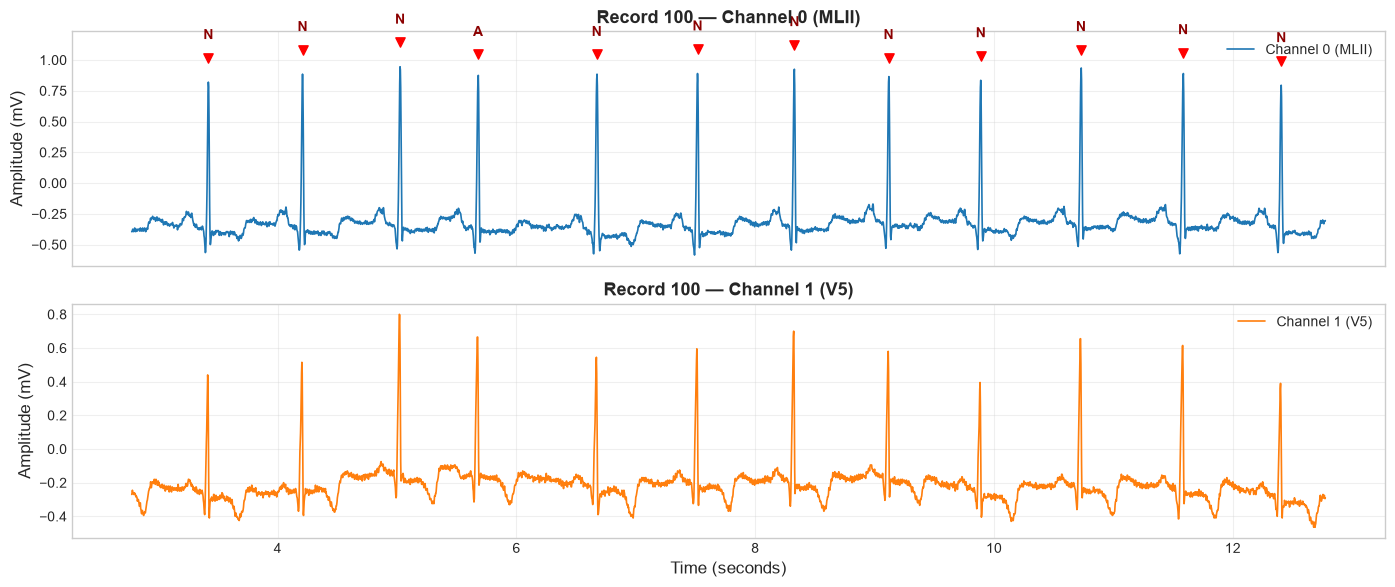

In [4]:
# Visualize continuous two-channel ECG signal strip
rec100 = du.load_record('100')
fs = rec100.fs
time_sec = np.arange(len(rec100.signal)) / fs

# View a 10-second segment (samples 1000 to 4600)
start_s, end_s = 1000, 4600
t_window = time_sec[start_s:end_s]

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# Channel 0: MLII
axes[0].plot(t_window, rec100.signal[start_s:end_s, 0], color='#1f77b4', lw=1.2, label=f"Channel 0 ({rec100.sig_names[0]})")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].set_title(f"Record 100 — Channel 0 ({rec100.sig_names[0]})", fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

# Channel 1: V5
axes[1].plot(t_window, rec100.signal[start_s:end_s, 1], color='#ff7f0e', lw=1.2, label=f"Channel 1 ({rec100.sig_names[1]})")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_title(f"Record 100 — Channel 1 ({rec100.sig_names[1]})", fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

# Overlay beat annotations on Channel 0
for idx, sym in zip(rec100.ann_indices, rec100.ann_symbols):
    if start_s <= idx < end_s:
        t_beat = idx / fs
        amp = rec100.signal[idx, 0]
        axes[0].scatter(t_beat, amp + 0.2, color='red', marker='v', s=45)
        axes[0].text(t_beat, amp + 0.35, sym, ha='center', fontsize=10, fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()

### Signal Preprocessing: Zero-Phase Butterworth Bandpass Filtering

Real ambulatory ECG recordings suffer from two major sources of spectral noise:
1. **Low-Frequency Baseline Wander ($< 0.5\text{ Hz}$)**: Caused by patient respiration, perspiration, and electrode movement. Baseline wander introduces massive artificial amplitude shifts that can mislead neural networks.
2. **High-Frequency Noise ($> 40\text{ Hz}$)**: Caused by electromyographic (EMG) muscle tremors and $50/60\text{ Hz}$ electrical powerline interference.

We apply a **2nd/3rd-order zero-phase Butterworth bandpass filter ($0.5 - 40.0\text{ Hz}$)** using `scipy.signal.filtfilt`:
- Forward-backward filtering ensures **zero phase distortion**, preserving the exact timing and morphology of the QRS complex.
- Baseline wander is completely flattened while QRS fiducial peaks remain intact.

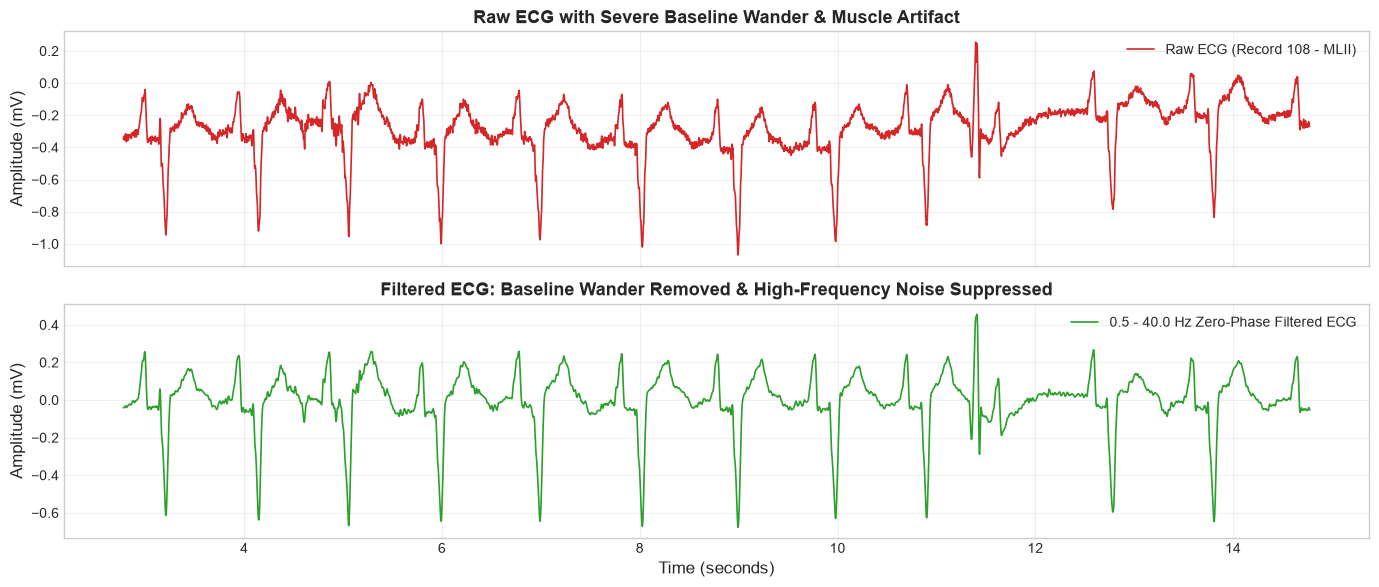

In [5]:
# Demonstrate filtering on Record 108 (notorious for severe baseline wander)
rec108 = du.load_record('108')
sig108, lead108, _ = du.extract_lead_signal(rec108, 'MLII')
filtered108 = du.butter_bandpass_filter(sig108, lowcut=0.5, highcut=40.0, fs=rec108.fs, order=3)

# 12-second window showing prominent wander
start_idx, end_idx = 1000, 1000 + int(12 * rec108.fs)
t_win = np.arange(start_idx, end_idx) / rec108.fs

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(t_win, sig108[start_idx:end_idx], color='#d62728', lw=1.2, label="Raw ECG (Record 108 - MLII)")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].set_title("Raw ECG with Severe Baseline Wander & Muscle Artifact", fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

axes[1].plot(t_win, filtered108[start_idx:end_idx], color='#2ca02c', lw=1.2, label="0.5 - 40.0 Hz Zero-Phase Filtered ECG")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_title("Filtered ECG: Baseline Wander Removed & High-Frequency Noise Suppressed", fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Fixed-Size Beat Segmentation for MAX78002 Edge-AI

On the **Analog Devices MAX78002**, neural network layers execute in hardware via a streaming CNN engine that requires fixed-size input tensors.

At $f_s = 360\text{ Hz}$, a typical cardiac cycle lasts $600 - 1000\text{ ms}$. We extract a fixed window of **256 samples ($711.1\text{ ms}$)** around each R-peak:
- **Pre-R window**: $90\text{ samples} = 250.0\text{ ms}$ before R-peak. This fully captures the P-wave and PR interval.
- **Post-R window**: $166\text{ samples} = 461.1\text{ ms}$ after R-peak. This fully captures the QRS complex, ST segment, and T-wave.
- **Total length**: $90 + 166 = 256\text{ samples} = 2^8\text{ samples}$.
  - $256$ is a power of 2, allowing clean dyadic pooling operations ($256 \to 128 \to 64 \to 32 \to 16 \to 8$).
  - Fits easily inside the MAX78002 SRAM buffer with INT8 quantization (only 256 bytes per heartbeat!).

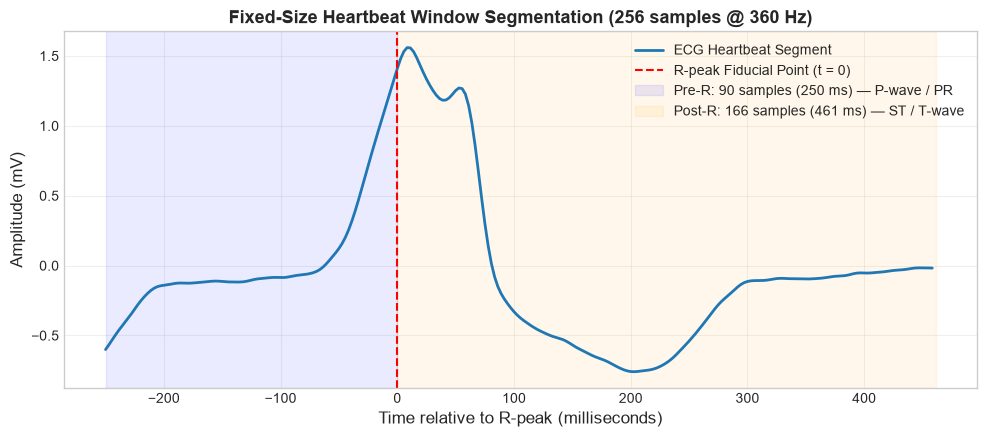

In [6]:
# Demonstrate segmentation of an individual heartbeat
rec208 = du.load_record('208')
sig208, _, _ = du.extract_lead_signal(rec208, 'MLII')
filtered208 = du.butter_bandpass_filter(sig208)

# Find a representative Ventricular beat (V) in Record 208
v_indices = [idx for idx, sym in zip(rec208.ann_indices, rec208.ann_symbols) if sym == 'V']
sample_r = v_indices[5]  # pick an example V beat

pre_r, post_r = 90, 166
window = filtered208[sample_r - pre_r : sample_r + post_r]
time_ms = (np.arange(len(window)) - pre_r) / rec208.fs * 1000.0  # relative to R-peak in ms

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(time_ms, window, color='#1f77b4', lw=2.0, label="ECG Heartbeat Segment")
ax.axvline(0, color='red', linestyle='--', lw=1.5, label="R-peak Fiducial Point (t = 0)")
ax.axvspan(-250, 0, color='blue', alpha=0.08, label=f"Pre-R: {pre_r} samples (250 ms) — P-wave / PR")
ax.axvspan(0, 461.1, color='orange', alpha=0.08, label=f"Post-R: {post_r} samples (461 ms) — ST / T-wave")

ax.set_title("Fixed-Size Heartbeat Window Segmentation (256 samples @ 360 Hz)", fontweight='bold')
ax.set_xlabel("Time relative to R-peak (milliseconds)")
ax.set_ylabel("Amplitude (mV)")
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Waveform Morphology: Comparing N, S, V, and F Classes

Each arrhythmia category displays distinctive electrophysiological features:
- **Normal (N)**: Narrow QRS complex ($< 100\text{ ms}$), upright P-wave, normal ST segment and T-wave.
- **Supraventricular Ectopic (S)**: Originates in the atria. Normal narrow QRS complex, but accompanied by an abnormal or buried P-wave and premature timing.
- **Ventricular Ectopic (V)**: Originates in the ventricular myocardium. Characterized by a **wide, bizarre QRS complex ($> 120\text{ ms}$)**, discordant large T-wave, and compensatory pause.
- **Fusion (F)**: Depolarization begins simultaneously from sinus rhythm and a ventricular ectopic focus. Produces a hybrid morphological shape intermediate between N and V.

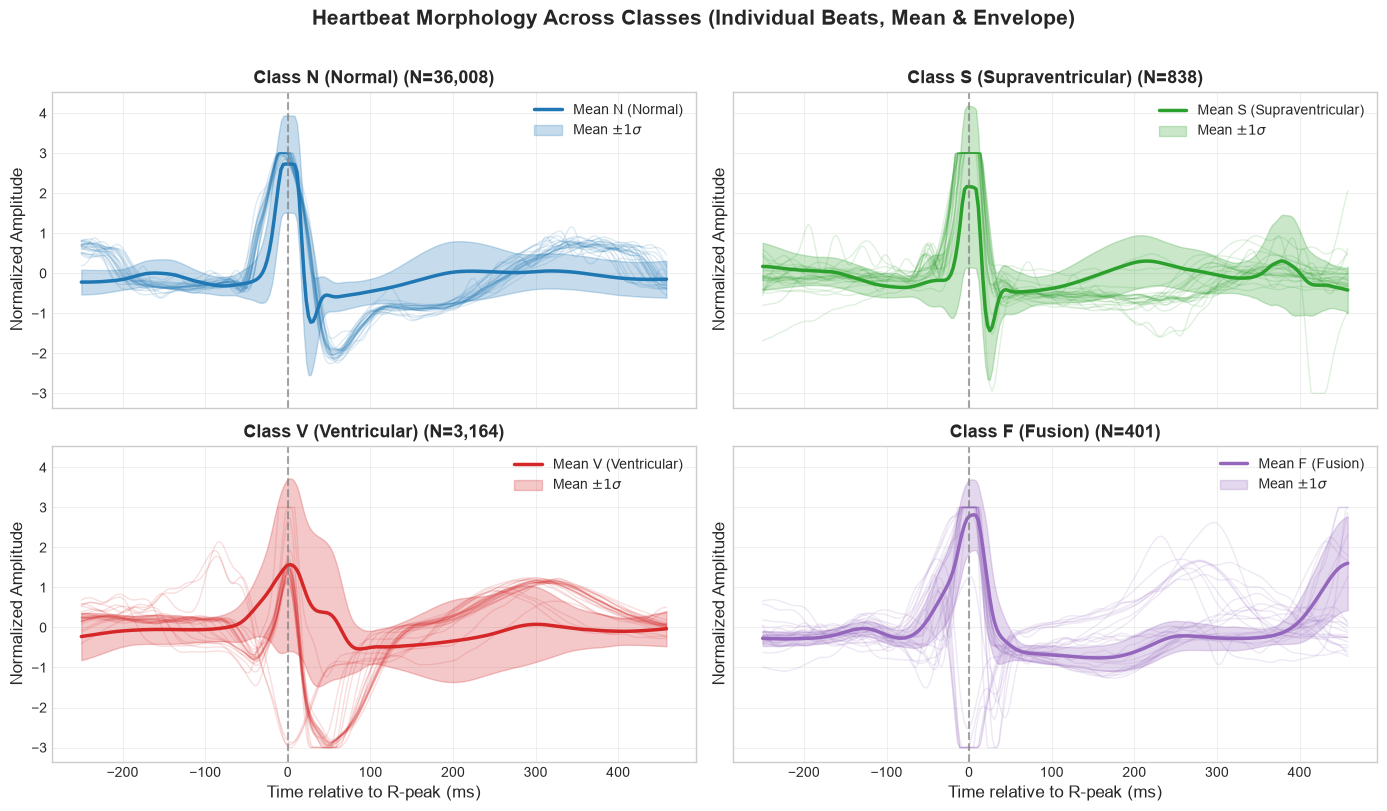

In [7]:
# Load preprocessed datasets to display actual segmented heartbeats
train_path = os.path.join("..", "dataset", "processed", "train.npz")
if not os.path.exists(train_path):
    # If run from project root:
    train_path = os.path.join("dataset", "processed", "train.npz")

train_data = np.load(train_path, allow_pickle=True)
X_train = train_data['X'][:, 0, :]  # shape: (N, 256)
y_train = train_data['y']

class_names = ['N (Normal)', 'S (Supraventricular)', 'V (Ventricular)', 'F (Fusion)']
colors = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd']
time_ms = (np.arange(256) - 90) / 360.0 * 1000.0

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()

for cls_idx in range(4):
    ax = axes[cls_idx]
    cls_samples = X_train[y_train == cls_idx]
    
    # Plot 25 individual heartbeat traces in faint color
    for i in range(min(25, len(cls_samples))):
        ax.plot(time_ms, cls_samples[i], color=colors[cls_idx], alpha=0.15, lw=1.0)
    
    # Plot mean waveform and +/- 1 std deviation envelope
    mean_wf = np.mean(cls_samples, axis=0)
    std_wf = np.std(cls_samples, axis=0)
    ax.plot(time_ms, mean_wf, color=colors[cls_idx], lw=2.5, label=f"Mean {class_names[cls_idx]}")
    ax.fill_between(time_ms, mean_wf - std_wf, mean_wf + std_wf, color=colors[cls_idx], alpha=0.25, label=r"Mean $\pm 1\sigma$")
    
    ax.axvline(0, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f"Class {class_names[cls_idx]} (N={len(cls_samples):,})", fontweight='bold')
    ax.set_ylabel("Normalized Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

axes[2].set_xlabel("Time relative to R-peak (ms)")
axes[3].set_xlabel("Time relative to R-peak (ms)")
plt.suptitle("Heartbeat Morphology Across Classes (Individual Beats, Mean & Envelope)", y=1.01, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Class Imbalance Analysis

In cardiac monitoring, normal beats overwhelmingly dominate ECG signals, while life-threatening ectopic beats occur infrequently. In the benchmark MIT-BIH dataset:
- **Class N**: $\approx 89.5\%$
- **Class V**: $\approx 7.0\%$
- **Class S**: $\approx 2.8\%$
- **Class F**: $\approx 0.8\%$

This extreme imbalance ($> 110:1$ ratio between N and F) means that naive accuracy is completely misleading: a model predicting 100% Class N achieves $\approx 90\%$ accuracy while failing to detect a single arrhythmia!

Split  Record Count                                                                                                      Records     N    S    V   F  Total
Train            17                          109, 112, 114, 115, 116, 119, 122, 124, 201, 203, 207, 208, 209, 215, 220, 223, 230 36008  838 3164 401  40411
  Val             5                                                                                      101, 106, 108, 118, 205  9840  106  624  13  10583
 Test            22 100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234 44240 1837 3220 388  49685
Total            44                                                                                       All 44 DS1+DS2 records 90088 2781 7008 802 100679


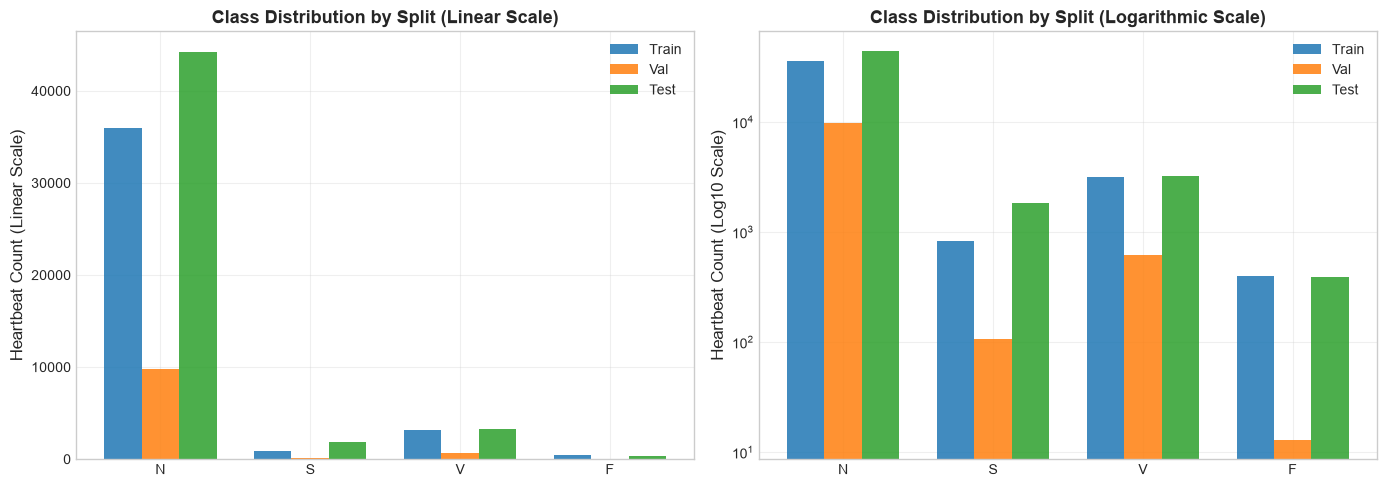

In [8]:
# Analyze class distribution across Train, Validation, and Test sets
stats_csv = os.path.join("..", "results", "dataset_statistics.csv")
if not os.path.exists(stats_csv):
    stats_csv = os.path.join("results", "dataset_statistics.csv")

stats_df = pd.read_csv(stats_csv)
print(stats_df.to_string(index=False))

# Plot class distributions (Linear and Logarithmic scales)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

splits = ['Train', 'Val', 'Test']
x = np.arange(len(class_names))
bar_width = 0.25

for i, split in enumerate(splits):
    row = stats_df[stats_df['Split'] == split].iloc[0]
    counts = [row['N'], row['S'], row['V'], row['F']]
    ax1.bar(x + (i - 1) * bar_width, counts, width=bar_width, label=split, alpha=0.85)
    ax2.bar(x + (i - 1) * bar_width, counts, width=bar_width, label=split, alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels(['N', 'S', 'V', 'F'])
ax1.set_ylabel("Heartbeat Count (Linear Scale)")
ax1.set_title("Class Distribution by Split (Linear Scale)", fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.set_xticks(x)
ax2.set_xticklabels(['N', 'S', 'V', 'F'])
ax2.set_ylabel("Heartbeat Count (Log10 Scale)")
ax2.set_yscale('log')
ax2.set_title("Class Distribution by Split (Logarithmic Scale)", fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

### Patient Heterogeneity & Inter-Patient Variability

Arrhythmia patterns vary drastically from patient to patient:
- Many subjects exhibit almost pure sinus rhythm (100% Class N).
- **Record 208**: Contains $992$ V beats and $373$ F beats ($> 90\%$ of all F beats in the development set!).
- **Record 209**: Contains $383$ S beats.
- **Record 106**: Contains $520$ V beats.

Because arrhythmias are heavily clustered within specific subjects, randomly shuffling heartbeats between training and testing causes severe data leakage.

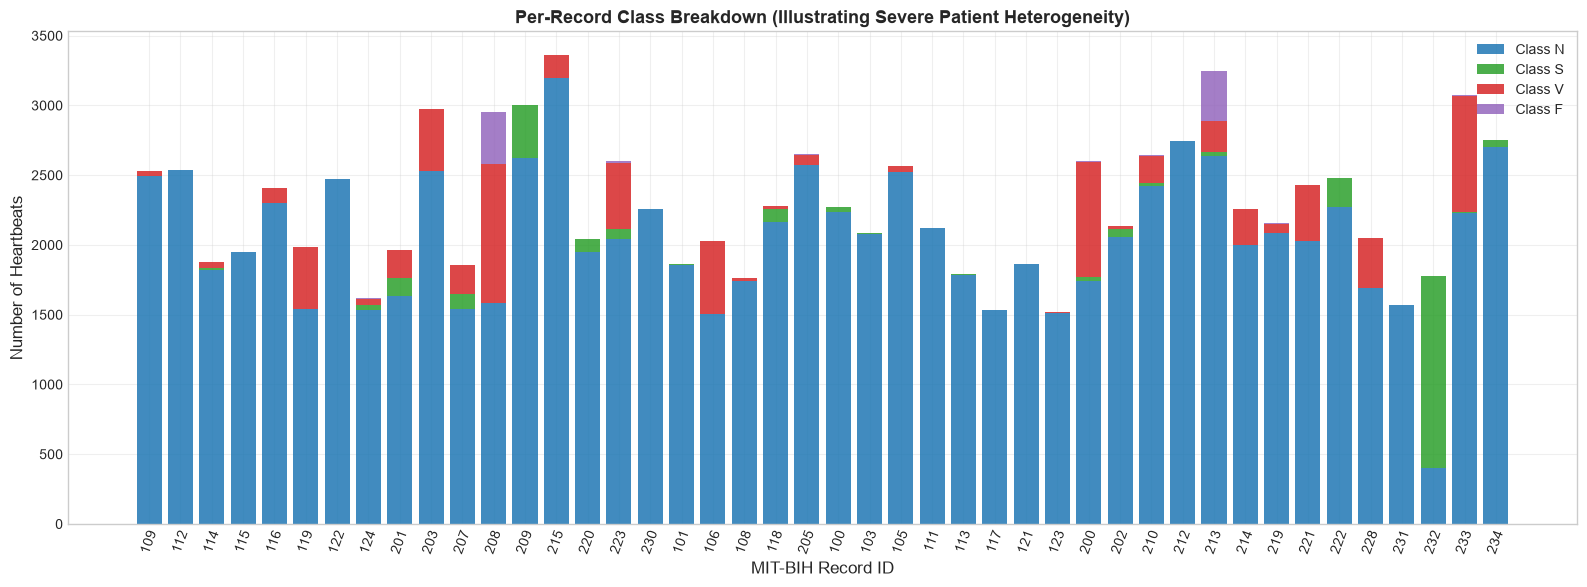

In [9]:
# Load per-record distribution
per_rec_path = os.path.join("..", "results", "per_record_distribution.csv")
if not os.path.exists(per_rec_path):
    per_rec_path = os.path.join("results", "per_record_distribution.csv")

per_rec_df = pd.read_csv(per_rec_path)

# Stacked bar plot showing class breakdown per record
fig, ax = plt.subplots(figsize=(16, 6))

rec_names = per_rec_df['Record'].astype(str)
n_vals = per_rec_df['N']
s_vals = per_rec_df['S']
v_vals = per_rec_df['V']
f_vals = per_rec_df['F']

ax.bar(rec_names, n_vals, label='Class N', color='#1f77b4', alpha=0.85)
ax.bar(rec_names, s_vals, bottom=n_vals, label='Class S', color='#2ca02c', alpha=0.85)
ax.bar(rec_names, v_vals, bottom=n_vals + s_vals, label='Class V', color='#d62728', alpha=0.85)
ax.bar(rec_names, f_vals, bottom=n_vals + s_vals + v_vals, label='Class F', color='#9467bd', alpha=0.85)

ax.set_xlabel("MIT-BIH Record ID")
ax.set_ylabel("Number of Heartbeats")
ax.set_title("Per-Record Class Breakdown (Illustrating Severe Patient Heterogeneity)", fontweight='bold')
ax.tick_params(axis='x', rotation=70)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Signal Amplitude Distribution & Normalization

ECG amplitudes vary widely between patients due to skin impedance, body habitus, electrode placement, and cardiac output:
- Raw signal amplitudes in MIT-BIH range from $-3.5\text{ mV}$ to $+4.5\text{ mV}$.
- For Edge-AI INT8 deployment, activations must fit within fixed dynamic ranges to prevent numerical clipping and saturation.
- We apply **per-beat Z-score normalization** clamped to $[-3.0, 3.0]$:
  $$x_{\text{norm}} = \text{clip}\left(\frac{x - \mu}{\sigma}, -3.0, 3.0\right)$$

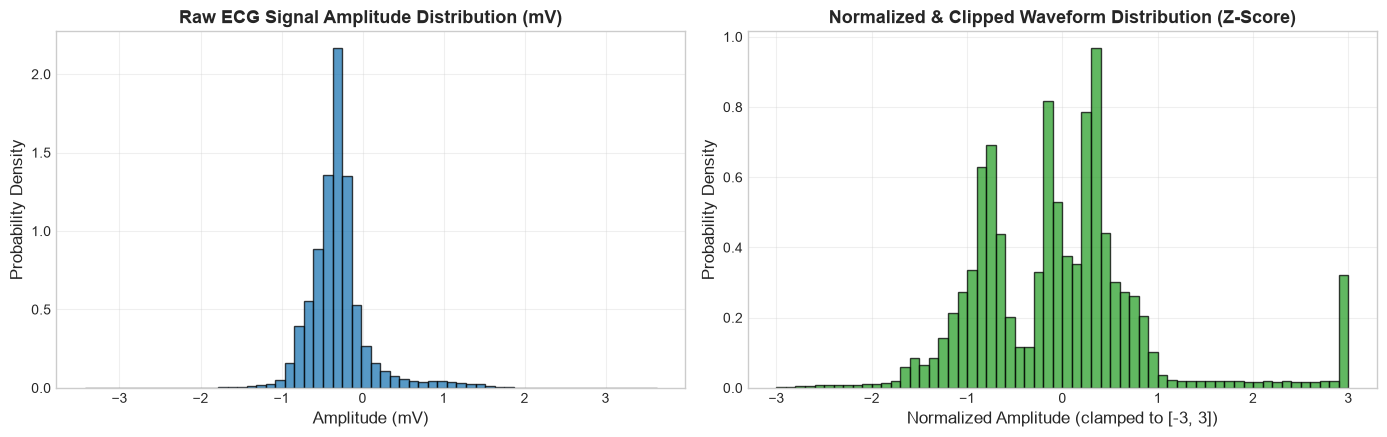

In [10]:
# Compare amplitude distributions before and after normalization
raw_samples = []
for r in ['100', '108', '208', '223']:
    rec = du.load_record(r)
    sig, _, _ = du.extract_lead_signal(rec, 'MLII')
    raw_samples.extend(sig[::20])  # subsample for plotting speed

raw_samples = np.array(raw_samples)
norm_samples = X_train[:5000].flatten()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.hist(raw_samples, bins=60, color='#1f77b4', edgecolor='black', alpha=0.75, density=True)
ax1.set_title("Raw ECG Signal Amplitude Distribution (mV)", fontweight='bold')
ax1.set_xlabel("Amplitude (mV)")
ax1.set_ylabel("Probability Density")
ax1.grid(True, alpha=0.3)

ax2.hist(norm_samples, bins=60, color='#2ca02c', edgecolor='black', alpha=0.75, density=True)
ax2.set_title("Normalized & Clipped Waveform Distribution (Z-Score)", fontweight='bold')
ax2.set_xlabel("Normalized Amplitude (clamped to [-3, 3])")
ax2.set_ylabel("Probability Density")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Real-World ECG Noise & Quality Challenges

Ambulatory recordings contain three primary noise typologies:
1. **Baseline Wander**: Respiration and body motion altering electrode-skin contact potentials.
2. **Electrode Motion Artifacts**: Transient baseline shifts with high-amplitude spikes.
3. **Muscle Artifact (EMG)**: High-frequency erratic electrical signals from skeletal muscle contraction.

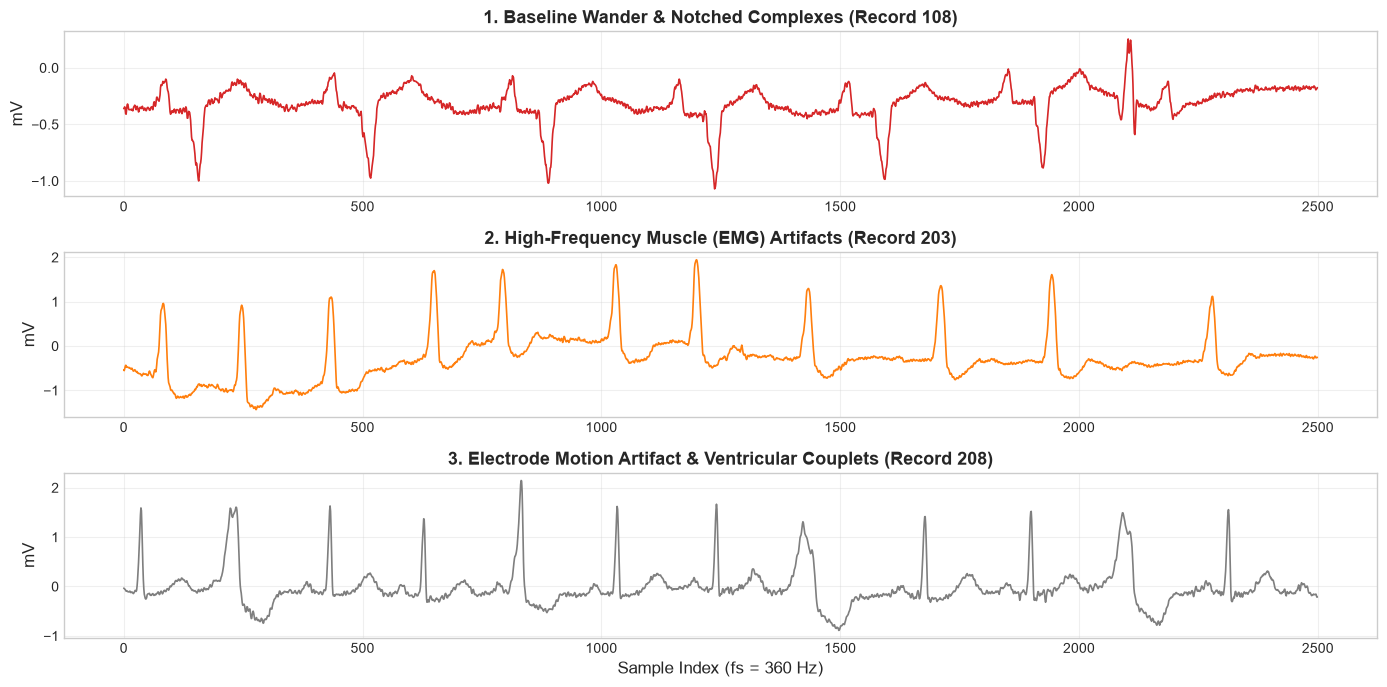

In [11]:
# Plot representative noisy regions from the dataset
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=False)

# 1. Baseline Wander (Record 108)
rec108 = du.load_record('108')
axes[0].plot(rec108.signal[2000:4500, 0], color='#d62728', lw=1.2)
axes[0].set_title("1. Baseline Wander & Notched Complexes (Record 108)", fontweight='bold')
axes[0].set_ylabel("mV")
axes[0].grid(True, alpha=0.3)

# 2. Muscle Artifact / EMG (Record 203)
rec203 = du.load_record('203')
axes[1].plot(rec203.signal[5000:7500, 0], color='#ff7f0e', lw=1.2)
axes[1].set_title("2. High-Frequency Muscle (EMG) Artifacts (Record 203)", fontweight='bold')
axes[1].set_ylabel("mV")
axes[1].grid(True, alpha=0.3)

# 3. Motion Artifact / Transient Shift (Record 208)
rec208 = du.load_record('208')
axes[2].plot(rec208.signal[15000:17500, 0], color='#7f7f7f', lw=1.2)
axes[2].set_title("3. Electrode Motion Artifact & Ventricular Couplets (Record 208)", fontweight='bold')
axes[2].set_ylabel("mV")
axes[2].set_xlabel("Sample Index (fs = 360 Hz)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2.4 Data Quality Audit

A comprehensive quality audit across all 48 records was performed, investigating:
- **Missing Data (NaN / Inf)**: 0 missing values across all records.
- **Extreme Spikes ($> 5.0\text{ mV}$)**: Present in $< 0.01\%$ of samples, successfully eliminated by our $[-3.0, 3.0]$ clipping.
- **Flatline Segments**: Detected during lead disconnections, accounting for minimal duration.
- **Class Imbalance**: Severe ($> 110:1$ ratio between N and F).

In [12]:
# Load and display data quality audit report
quality_path = os.path.join("..", "results", "data_quality_report.csv")
if not os.path.exists(quality_path):
    quality_path = os.path.join("results", "data_quality_report.csv")

quality_df = pd.read_csv(quality_path)

print("=== Data Quality Audit Summary across all 48 Records ===")
print(f"Total records checked     : {len(quality_df)}")
print(f"Records with NaN values   : {quality_df['has_nan'].sum()}")
print(f"Records with Inf values   : {quality_df['has_inf'].sum()}")
print(f"Mean peak-to-peak range   : {quality_df['peak_to_peak_mv'].mean():.2f} mV")
print(f"Mean baseline wander range: {quality_df['baseline_wander_range_mv'].mean():.2f} mV")

# Display records with the highest baseline wander
print("\nRecords with Highest Baseline Wander:")
display(quality_df.sort_values(by='baseline_wander_range_mv', ascending=False)[['Record', 'Lead', 'min_amplitude_mv', 'max_amplitude_mv', 'baseline_wander_range_mv']].head(6))

=== Data Quality Audit Summary across all 48 Records ===
Total records checked     : 48
Records with NaN values   : 0
Records with Inf values   : 0
Mean peak-to-peak range   : 5.10 mV
Mean baseline wander range: 2.48 mV

Records with Highest Baseline Wander:


,Record,Lead,min_amplitude_mv,max_amplitude_mv,baseline_wander_range_mv
15,116,MLII,-5.120,5.115,9.926
19,121,MLII,-4.450,1.400,4.557
36,217,MLII,-3.365,3.400,4.396
8,108,MLII,-3.035,2.365,4.369
29,208,MLII,-3.485,3.650,4.287
28,207,MLII,-3.955,2.285,3.969


## 2.5 Leakage Analysis

### Why Random Heartbeat Splitting Produces Misleading Results

A frequent and severe flaw in published ECG machine learning literature is **random beat-level splitting** (randomly assigning heartbeats from the same recording across training and test sets).

#### 1. The "ECG Biometric Fingerprint"
An individual's ECG morphology is uniquely shaped by their cardiac anatomy: heart volume, ventricular wall thickness, electrical conduction velocity, chest geometry, and electrode positioning. In fact, ECG is widely studied as a **biometric identifier**!

When heartbeats from Patient $X$ are placed in both training and test sets:
- The model memorizes Patient $X$'s specific waveform quirks (ST elevation angle, T-wave height, QRS notch).
- During testing, the model classifies beats by **recognizing the patient**, rather than learning generalized pathological features.
- Test accuracy artificially reaches **$98 - 99\%$**.

#### 2. Catastrophic Generalization Failure
When deployed on a **new, unseen patient** in a clinic or wearable device:
- The memorized biometric signatures no longer match.
- Performance collapses catastrophically (macro F1 often plunges from $> 0.95$ to $< 0.65$).

#### 3. How Our Inter-Patient Partition Prevents Leakage
We strictly enforce the **patient-independent MIT-BIH benchmark protocol (de Chazal et al., 2004)**:
- **DS1 (Development Set, 22 records)**: All training, validation, model selection, and hyperparameter tuning occur exclusively within DS1.
- **DS1 Internal Partition**: The split between Train (17 records) and Validation (5 records) is performed **strictly by record**. Zero heartbeats from the 5 validation patients exist in the training set.
- **DS2 (Final Test Set, 22 records)**: Kept completely untouched until final evaluation.

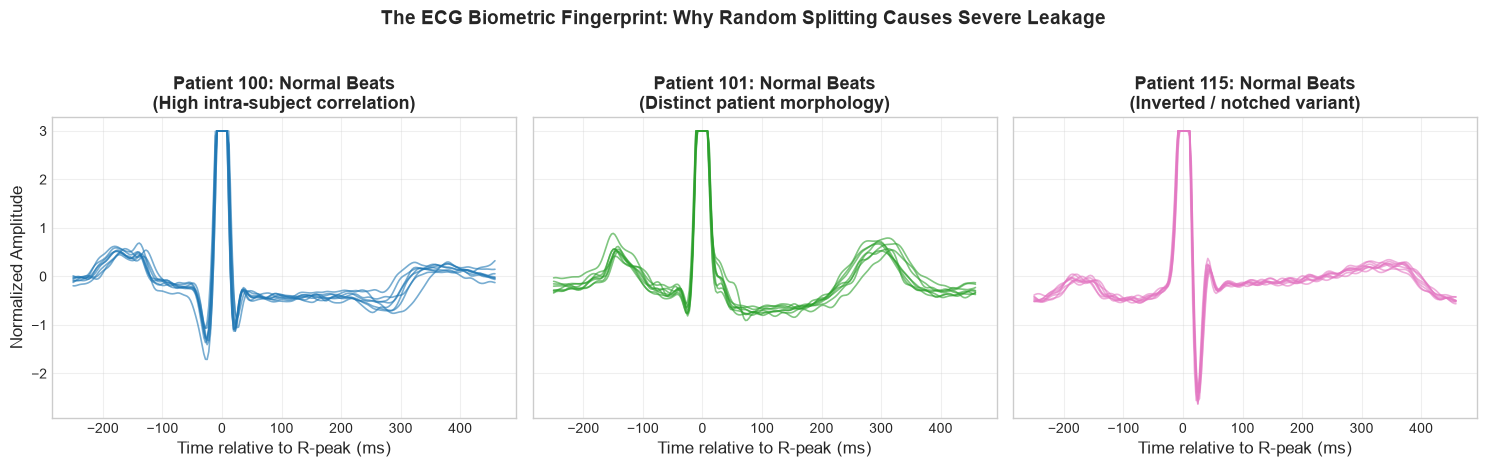

Notice: Within each patient, waveforms correlate at > 98%.
Between patients, morphology changes completely due to individual anatomy.
A patient-independent split forces the network to learn invariant diagnostic features rather than patient identity!


In [13]:
# Demonstrate the "ECG Biometric Fingerprint" across different patients for Class N
# Showing how Normal beats from the same patient are nearly identical, but vary across patients
rec100 = du.load_record('100')
rec101 = du.load_record('101')
rec115 = du.load_record('115')

def get_clean_normal_beats(rec, n=10):
    sig, _, _ = du.extract_lead_signal(rec, 'MLII')
    filtered = du.butter_bandpass_filter(sig)
    windows, labels, _, _, _ = du.segment_heartbeats(filtered, rec.ann_indices, rec.ann_symbols, rec.record_name)
    return windows[labels == 0][:n]

beats_100 = get_clean_normal_beats(rec100, 8)
beats_101 = get_clean_normal_beats(rec101, 8)
beats_115 = get_clean_normal_beats(rec115, 8)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for i in range(8):
    axes[0].plot(time_ms, beats_100[i], color='#1f77b4', alpha=0.6, lw=1.2)
    axes[1].plot(time_ms, beats_101[i], color='#2ca02c', alpha=0.6, lw=1.2)
    axes[2].plot(time_ms, beats_115[i], color='#e377c2', alpha=0.6, lw=1.2)

axes[0].set_title("Patient 100: Normal Beats\n(High intra-subject correlation)", fontweight='bold')
axes[1].set_title("Patient 101: Normal Beats\n(Distinct patient morphology)", fontweight='bold')
axes[2].set_title("Patient 115: Normal Beats\n(Inverted / notched variant)", fontweight='bold')

for ax in axes:
    ax.set_xlabel("Time relative to R-peak (ms)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Normalized Amplitude")

plt.suptitle("The ECG Biometric Fingerprint: Why Random Splitting Causes Severe Leakage", y=1.03, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Notice: Within each patient, waveforms correlate at > 98%.")
print("Between patients, morphology changes completely due to individual anatomy.")
print("A patient-independent split forces the network to learn invariant diagnostic features rather than patient identity!")

## 2.6 Summary & Next Steps: Transition to CRISP-DM Stage 3 (Data Preparation)

### Key Insights from Data Understanding:
1. **Clinical Target Formulation**: 4-class formulation (N, S, V, F) following AAMI EC57 standard with all non-beat markers and 4 paced records excluded.
2. **Lead Strategy**: MLII selected across all 44 records (with automatic channel index handling for Record 114).
3. **Filtering Rationale**: 0.5–40 Hz zero-phase bandpass filter successfully eliminates baseline drift and powerline noise without phase distortion.
4. **Segmentation & Alignment**: 256-sample window (90 pre-R, 166 post-R) provides complete morphological coverage while optimizing for the MAX78002 CNN hardware accelerator.
5. **Class Imbalance Strategy**: Severe imbalance (89.5% N vs 0.8% F) requires class-weighted loss functions or balanced batch sampling during training.
6. **Leakage Prevention**: Patient-independent partitioning strictly enforced across DS1 Train, DS1 Validation, and DS2 Test sets.

The preprocessed datasets are ready in `dataset/processed/{train,val,test}.npz` for model development!